# 01 · Data understanding and preprocessing

What the data looks like and which observations drive later choices (input resolution, anchors,
detections per image, augmentation, frame sampling, validation split). Runs on CPU in a few minutes.

Inputs: competition data + `prepared/` tables written by `python -m visdet.prepare` (notebook 02).
All sizes below are in **test-scale pixels** (frames halved until the long side is ≤ 1920 px,
like the test frames), unless stated otherwise. Figures are saved to `images/` for the report.

In [1]:
# Setup: tables from the preprocessing step, plotting style
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2

from visdet.data import CLASSES, find_raw_root, read_prepared
from visdet.plotting import setup_style, save, draw_boxes, show_bgr, SERIES, INK_2

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PREP, FIG = find_raw_root(), ROOT / "prepared", ROOT / "images"
setup_style()
pd.set_option("display.precision", 3)

images, boxes, folds = read_prepared(PREP)
boxes = boxes.merge(images[["image_id", "clip", "frame", "split", "out_w", "out_h"]], on="image_id")
obj, crowd = boxes[boxes.iscrowd == 0].copy(), boxes[boxes.iscrowd == 1]
obj["size"] = np.sqrt(obj.w * obj.h)                      # sqrt(area), test-scale px
obj["cls_name"] = pd.Categorical(np.array(CLASSES)[obj.cls], CLASSES)
test = pd.read_csv(RAW / "test_images.csv")
print(f"{images["clip"].nunique()} labelled clips, {len(images)} frames, {len(obj)} objects, {len(crowd)} ignore regions")

63 labelled clips, 27047 frames, 1219648 objects, 67838 ignore regions


## 1. Splits and the resolution shift

The labelled clips are stored at their original resolution (up to 3840×2160), but **test frames are
downscaled**: no test frame is wider than 1920 px and some clips are 680×382 or 960×540.
Halving every labelled frame until it fits 1920 px reproduces the main test resolution groups
exactly (2688→1344, 2720→1360, 3840→1920), so all training and validation frames are converted to
that scale. The remaining 680/960-px test clips motivate a down-scaling augmentation (notebook 07).

In [2]:
# Frames per resolution group (keyed by width: 1904x1071 and 1904x1072 differ only by rounding)
tab = pd.DataFrame({
    "labelled (original)": images.width.value_counts(),
    "labelled (converted)": images.out_w.value_counts(),
    "test": test.width.value_counts(),
}).fillna(0).astype(int).sort_index(ascending=False)
heights = pd.concat([images[["width", "height"]], images[["out_w", "out_h"]].set_axis(["width", "height"], axis=1),
                     test[["width", "height"]]]).groupby("width").height.min()
tab.index = [f"{w}×{heights[w]}" for w in tab.index]
split_stats = images.groupby("split").agg(clips=("clip", "nunique"), frames=("frame", "size"))
split_stats.loc["test"] = [test["clip"].nunique(), len(test)]
display(split_stats.T)
tab

split,train,val,test
clips,56,7,48
frames,24201,2846,3811


,labelled (original),labelled (converted),test
3840×2160,978,0,0
2720×1530,822,0,0
2688×1512,3738,0,0
1920×1080,721,1699,991
1904×1071,13354,13354,305
1360×764,962,1784,1474
1344×756,6472,10210,441
960×540,0,0,279
680×382,0,0,321


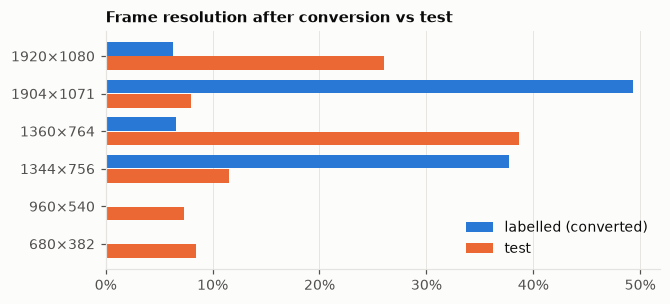

In [3]:
# Share of frames per resolution: converted labelled frames vs test frames
share = tab[["labelled (converted)", "test"]] / tab[["labelled (converted)", "test"]].sum()
share = share[(share > 0).any(axis=1)]
fig, ax = plt.subplots(figsize=(6.5, 2.8))
y = np.arange(len(share))
for k, col in enumerate(share.columns):
    ax.barh(y + (k - 0.5) * 0.38, share[col], height=0.36, color=SERIES[k], label=col)
ax.set_yticks(y, share.index); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Frame resolution after conversion vs test"); ax.legend(loc="lower right")
save(fig, "eda_resolution", FIG)

## 2. Class distribution

VisDrone's 10 classes are merged into 8 (pedestrian + people → person, tricycle + awning-tricycle →
tricycle); "ignored regions" and "others" become class-agnostic ignore regions.

cls_name,person,bicycle,car,van,truck,tricycle,bus,motor
objects,379013.000,46277.000,537122.00,53782.000,31857.000,46836.000,9917.000,114844.000
share,0.311,0.038,0.44,0.044,0.026,0.038,0.008,0.094
clips containing,62.000,46.000,55.00,52.000,44.000,44.000,25.000,56.000


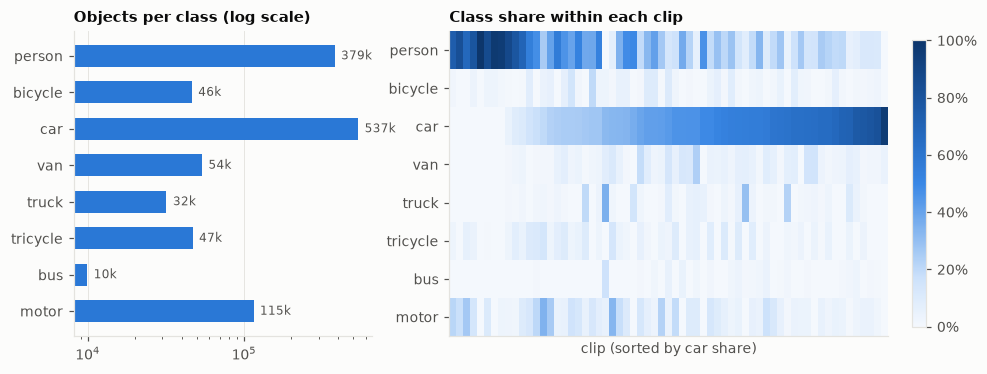

In [4]:
# Object counts per class and per-clip class mix
counts = obj.cls_name.value_counts().reindex(CLASSES)
clip_mix = pd.crosstab(obj["clip"], obj.cls_name, normalize="index")[CLASSES]
clip_mix = clip_mix.loc[clip_mix["car"].sort_values().index]

fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [1, 1.6]})
a.barh(CLASSES, counts, color=SERIES[0], height=0.6)
a.invert_yaxis(); a.grid(axis="y", visible=False); a.set_xscale("log")
for i, v in enumerate(counts): a.text(v * 1.1, i, f"{v/1e3:.0f}k", va="center", fontsize=8, color=INK_2)
a.set_title("Objects per class (log scale)")
im = b.imshow(clip_mix.T.values, aspect="auto", vmin=0, vmax=1)
b.set_yticks(range(len(CLASSES)), CLASSES); b.set_xticks([]); b.grid(False)
b.set_xlabel("clip (sorted by car share)"); b.set_title("Class share within each clip")
fig.colorbar(im, ax=b, fraction=0.03, format=plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
save(fig, "eda_classes", FIG)

n_clips = (pd.crosstab(obj["clip"], obj.cls_name) > 0).sum().reindex(CLASSES)
pd.DataFrame({"objects": counts, "share": counts / counts.sum(), "clips containing": n_clips}).T

## 3. Object sizes

COCO's size buckets (small < 32², medium < 96²) are applied in test-scale pixels, which is how the
leaderboard frames will be scored. The anchor/stride discussion uses sizes at the **network input**
(long side 1280 px), the benchmark protocol resolution.

size,small,medium,large,median sqrt-area (1280 input)
cls_name,,,,
person,0.484,0.512,0.003,25.342
bicycle,0.441,0.553,0.006,26.402
car,0.286,0.589,0.125,35.883
van,0.271,0.615,0.114,34.424
truck,0.115,0.593,0.292,49.383
tricycle,0.247,0.661,0.092,38.393
bus,0.053,0.503,0.443,69.149
motor,0.449,0.542,0.009,25.710
all,0.360,0.563,0.077,30.572


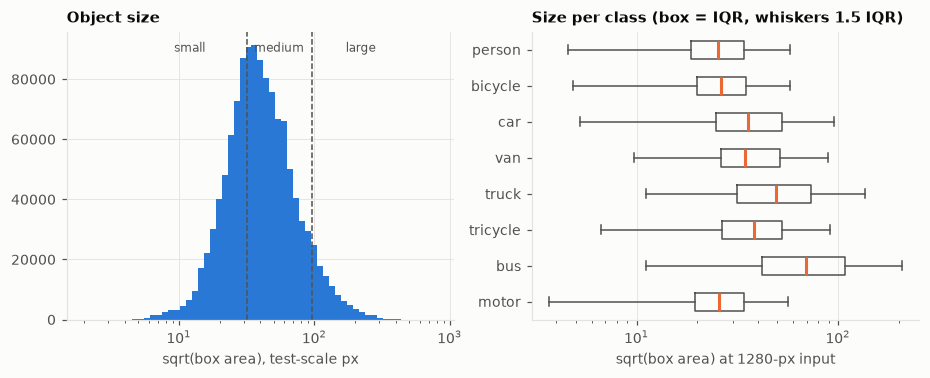

In [5]:
# sqrt(area) distribution, per-class sizes and COCO size buckets
obj["size_in"] = obj["size"] * 1280 / np.maximum(obj.out_w, obj.out_h)   # at 1280-px network input
bins = np.logspace(np.log10(2), np.log10(800), 60)
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.4))
a.hist(obj["size"], bins=bins, color=SERIES[0])
a.set_xscale("log"); a.set_xlabel("sqrt(box area), test-scale px"); a.set_title("Object size")
for t in (32, 96):
    a.axvline(t, color=INK_2, lw=1, ls="--")
for x, lab in ((12, "small"), (55, "medium"), (220, "large")):
    a.text(x, a.get_ylim()[1] * 0.93, lab, fontsize=8, color=INK_2, ha="center")
data = [obj.loc[obj.cls == c, "size_in"].values for c in range(len(CLASSES))]
b.boxplot(data, orientation="horizontal", tick_labels=CLASSES, showfliers=False, widths=0.5,
          medianprops=dict(color=SERIES[1], lw=2), boxprops=dict(color=INK_2), whiskerprops=dict(color=INK_2), capprops=dict(color=INK_2))
b.invert_yaxis(); b.set_xscale("log"); b.grid(axis="y", visible=False)
b.set_xlabel("sqrt(box area) at 1280-px input"); b.set_title("Size per class (box = IQR, whiskers 1.5 IQR)")
save(fig, "eda_sizes", FIG)

bucket = pd.cut(obj["size"], [0, 32, 96, np.inf], labels=["small", "medium", "large"])
size_tab = pd.crosstab(obj.cls_name, bucket, normalize="index")
size_tab.loc["all"] = bucket.value_counts(normalize=True)
size_tab["median sqrt-area (1280 input)"] = obj.groupby("cls_name", observed=True).size_in.median().reindex(size_tab.index).fillna(obj.size_in.median())
size_tab

In [6]:
# Box width/height and aspect ratio at the network input -> anchor sizes and ratios
w_in = obj.w * 1280 / np.maximum(obj.out_w, obj.out_h)
h_in = obj.h * 1280 / np.maximum(obj.out_w, obj.out_h)
q = [0.05, 0.25, 0.5, 0.75, 0.95]
anchors = pd.DataFrame({"width": w_in.quantile(q), "height": h_in.quantile(q), "sqrt area": obj.size_in.quantile(q)}).T
anchors.columns = [f"p{int(x*100)}" for x in q]
ratio = (obj.h / obj.w).groupby(obj.cls_name, observed=True).median()
display(anchors.round(1))
print("median aspect ratio h/w per class:", ratio.round(2).to_dict())
print(f"share of objects with sqrt-area < 16 px at 1280 input: {(obj.size_in < 16).mean():.1%}, < 32 px: {(obj.size_in < 32).mean():.1%}")

,p5,p25,p50,p75,p95
width,10.5,18.8,29.5,47.7,102.9
height,13.6,22.9,32.3,46.4,82.7
sqrt area,13.5,21.8,30.6,44.0,82.7


median aspect ratio h/w per class: {'person': 2.0, 'bicycle': 1.08, 'car': 0.79, 'van': 0.88, 'truck': 0.93, 'tricycle': 0.95, 'bus': 0.96, 'motor': 1.24}
share of objects with sqrt-area < 16 px at 1280 input: 9.7%, < 32 px: 53.6%


## 4. Scene density

The number of objects per frame decides the detection cap (torchvision keeps 100 by default,
Ultralytics 300) and the number of queries of a DETR-style model.

{'count': 27047.0, 'mean': 45.1, 'std': 31.1, 'min': 0.0, '50%': 42.0, '90%': 90.0, '99%': 140.0, 'max': 180.0}


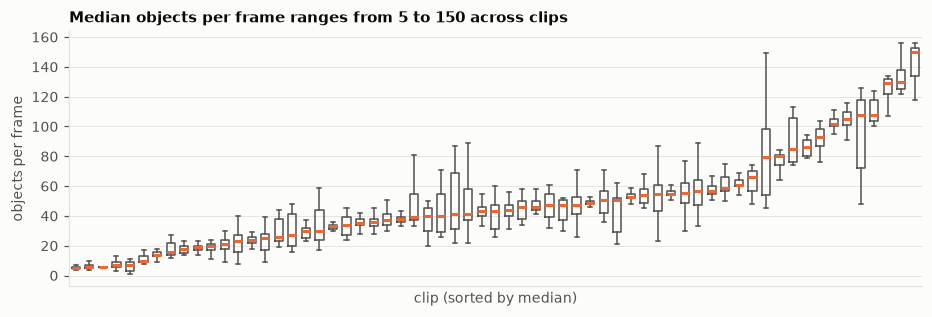

In [7]:
# Objects per frame, per clip
per_frame = obj.groupby("image_id").size().reindex(images.image_id, fill_value=0)
dens = images.assign(n=per_frame.values)
order = dens.groupby("clip").n.median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 3))
ax.boxplot([dens.loc[dens["clip"] == c, "n"] for c in order], showfliers=False, widths=0.6,
           medianprops=dict(color=SERIES[1], lw=2), boxprops=dict(color=INK_2), whiskerprops=dict(color=INK_2), capprops=dict(color=INK_2))
ax.set_xticks([]); ax.set_xlabel("clip (sorted by median)"); ax.set_ylabel("objects per frame")
med = dens.groupby("clip").n.median()
ax.set_title(f"Median objects per frame ranges from {med.min():.0f} to {med.max():.0f} across clips")
save(fig, "eda_density", FIG)
print(dens.n.describe(percentiles=[0.5, 0.9, 0.99]).round(1).to_dict())

## 5. Ignore regions and occlusion

In [8]:
# Ignore-region coverage and objects hidden by them; occlusion levels
cov = crowd.assign(a=crowd.w * crowd.h).groupby("image_id").a.sum() / (images.set_index("image_id").out_w * images.set_index("image_id").out_h)
has_ign = images.image_id.isin(crowd.image_id)
prepared = obj[obj.ign_frac.notna()]
print(f"frames with ignore regions: {has_ign.mean():.1%} (clips: {images[has_ign]["clip"].nunique()}/{images["clip"].nunique()})")
print(f"ignore regions per such frame: {crowd.groupby('image_id').size().median():.0f} median; "
      f"area covered: {cov.dropna().median():.1%} median, {cov.dropna().quantile(0.95):.1%} p95 (sum of boxes, overlaps double-counted)")
print(f"objects > 50% inside ignore regions (dropped from training labels): {(~prepared.keep).mean():.2%} "
      f"(measured on the {prepared.image_id.nunique()} prepared frames)")
occ = pd.crosstab(obj.cls_name, obj.occlusion.map({0: "none", 1: "partial", 2: "heavy"}), normalize="index")
occ[["none", "partial", "heavy"]].T

frames with ignore regions: 72.2% (clips: 55/63)
ignore regions per such frame: 2 median; area covered: 1.6% median, 11.0% p95 (sum of boxes, overlaps double-counted)
objects > 50% inside ignore regions (dropped from training labels): 1.24% (measured on the 2734 prepared frames)


cls_name,person,bicycle,car,van,truck,tricycle,bus,motor
occlusion,,,,,,,,
none,0.530,0.417,0.562,0.549,0.346,0.417,0.566,0.519
partial,0.409,0.551,0.389,0.415,0.498,0.556,0.413,0.417
heavy,0.061,0.032,0.049,0.035,0.156,0.026,0.020,0.064


## 6. Temporal redundancy → frame sampling step

Consecutive frames are near-duplicates. The IoU of the same track (`track_id`) between frame *t* and
*t + k* measures how much new information a frame *k* steps later adds.

k,1,2,3,5,10,15,20,30,50
median IoU,0.895,0.806,0.727,0.591,0.348,0.194,0.093,0.000,0.000
share IoU > 0.7,0.854,0.664,0.534,0.391,0.252,0.200,0.172,0.142,0.116


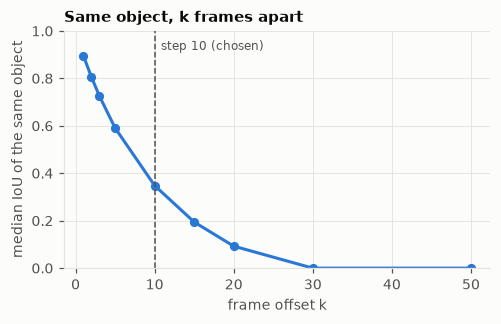

In [9]:
# Median IoU of the same object between frame t and t+k
def iou_xywh(a, b):
    x1 = np.maximum(a[:, 0], b[:, 0]); y1 = np.maximum(a[:, 1], b[:, 1])
    x2 = np.minimum(a[:, 0] + a[:, 2], b[:, 0] + b[:, 2]); y2 = np.minimum(a[:, 1] + a[:, 3], b[:, 1] + b[:, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    return inter / (a[:, 2] * a[:, 3] + b[:, 2] * b[:, 3] - inter)

tr = obj[obj.track_id >= 0][["clip", "track_id", "frame", "x", "y", "w", "h"]]
steps = [1, 2, 3, 5, 10, 15, 20, 30, 50]
rows = []
for k in steps:
    m = tr.merge(tr.assign(frame=tr.frame - k), on=["clip", "track_id", "frame"], suffixes=("", "_k"))
    v = iou_xywh(m[["x", "y", "w", "h"]].values, m[["x_k", "y_k", "w_k", "h_k"]].values)
    rows.append({"k": k, "median IoU": np.median(v), "share IoU > 0.7": (v > 0.7).mean()})
temporal = pd.DataFrame(rows).set_index("k")
fig, ax = plt.subplots(figsize=(5, 2.8))
ax.plot(temporal.index, temporal["median IoU"], marker="o", ms=5, color=SERIES[0])
ax.axvline(10, color=INK_2, lw=1, ls="--"); ax.text(10.8, 0.92, "step 10 (chosen)", fontsize=8, color=INK_2)
ax.set_xlabel("frame offset k"); ax.set_ylabel("median IoU of the same object"); ax.set_ylim(0, 1)
ax.set_title("Same object, k frames apart")
save(fig, "eda_temporal", FIG)
temporal.T

## 7. Validation design: clip-level folds

Frames of one clip are near-duplicates (section 6), so a frame-level split would leak. All 63
labelled clips (train + val) are assigned to 5 folds by `StratifiedKFold` on clips, stratified on
density tercile × person-heavy (`visdet.data.make_folds`). Fold 0 is the fixed benchmark split for
all detector comparisons; final candidates are confirmed on more folds.

In [10]:
# Fold composition
fold_tab = (dens  # images.csv already carries the fold of each clip
            .assign(person=lambda d: d.image_id.map(obj[obj.cls == 0].groupby("image_id").size()).fillna(0))
            .groupby("fold").agg(clips=("clip", "nunique"), frames=("frame", "size"), obj_per_frame=("n", "mean"),
                                 max_obj=("n", "max"), person_share=("person", "sum"), objects=("n", "sum")))
fold_tab["person_share"] /= fold_tab.pop("objects")
fold_tab.round(2).T

fold,0,1,2,3,4
clips,13.00,13.00,13.00,12.00,12.00
frames,5951.00,4412.00,5492.00,4810.00,6382.00
obj_per_frame,45.93,46.46,40.85,53.48,40.70
max_obj,134.00,156.00,174.00,180.00,113.00
person_share,0.35,0.25,0.22,0.32,0.38


## 8. Checking the conversion

Left: original frame with the original COCO boxes. Right: converted frame (test scale, ignore regions
filled gray) with the YOLO labels used for training. Boxes > 50 % inside an ignore region are dropped;
the pixels of kept boxes are never painted over.

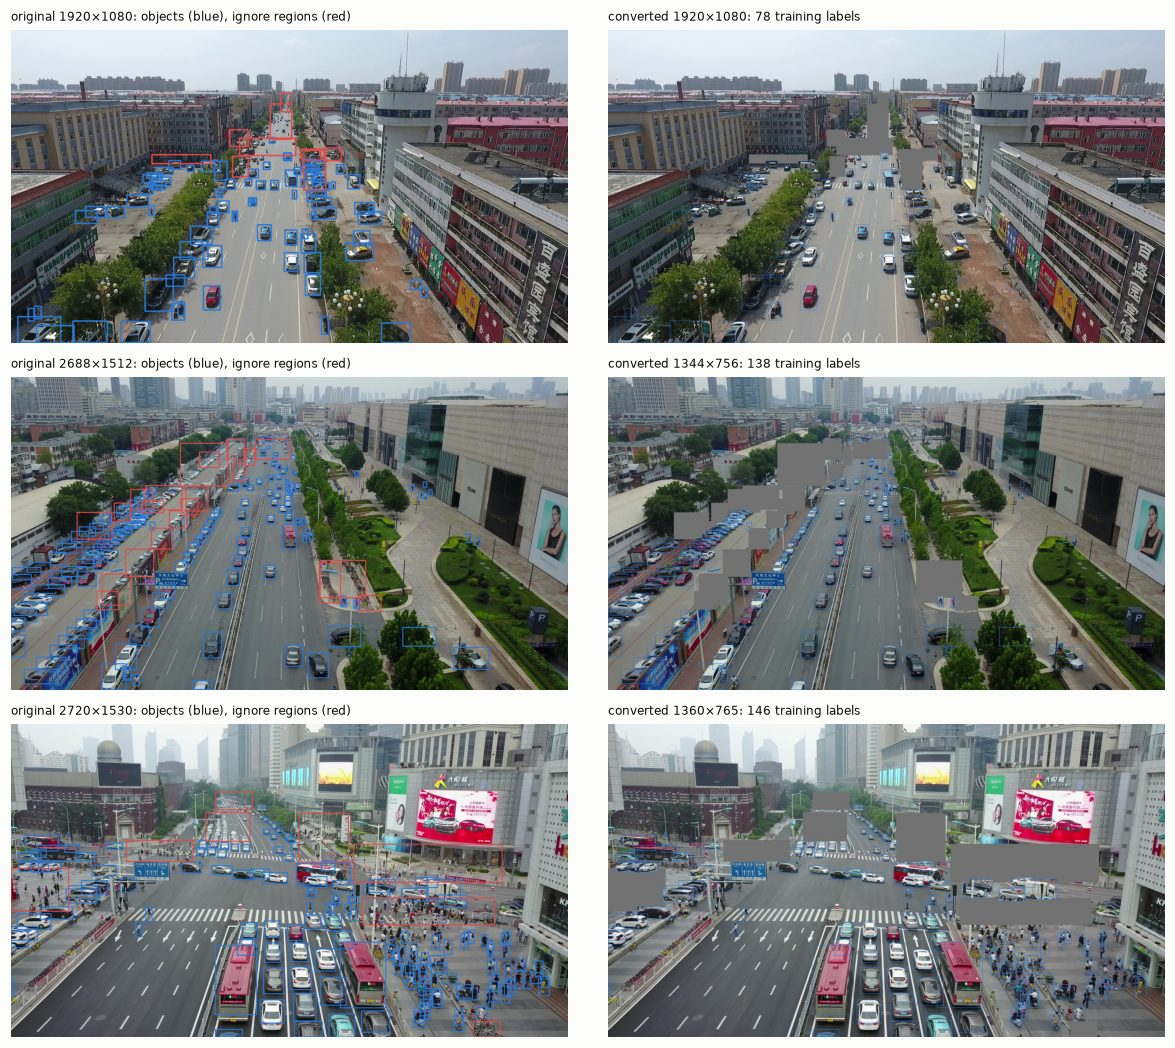

In [11]:
# Raw vs converted frames from three resolution groups
picks = (images[images.prepared].merge(crowd.groupby("image_id").size().rename("n_ign"), on="image_id")
         .sort_values("n_ign").groupby(["width"]).tail(1).sort_values("width").tail(3))
fig, axes = plt.subplots(len(picks), 2, figsize=(11, 3.2 * len(picks)))
for (_, r), (a, b) in zip(picks.iterrows(), axes):
    raw = cv2.imread(str(RAW / r.file_name))
    s = 1 / r.scale
    bx = boxes[boxes.image_id == r.image_id]
    draw_boxes(raw, bx[bx.iscrowd == 0][["x", "y", "w", "h"]].values * s, (214, 120, 42), 3)
    draw_boxes(raw, bx[bx.iscrowd == 1][["x", "y", "w", "h"]].values * s, (72, 73, 227), 4)
    show_bgr(a, raw, f"original {r.width}×{r.height}: objects (blue), ignore regions (red)")
    img = cv2.imread(str(PREP / r["path"])); H, W = img.shape[:2]
    lbl = np.loadtxt(PREP / "labels" / r["clip"] / (Path(r["path"]).stem + ".txt"), ndmin=2)
    xywh = np.c_[(lbl[:, 1] - lbl[:, 3] / 2) * W, (lbl[:, 2] - lbl[:, 4] / 2) * H, lbl[:, 3] * W, lbl[:, 4] * H]
    draw_boxes(img, xywh, (214, 120, 42), 1)
    show_bgr(b, img, f"converted {W}×{H}: {len(lbl)} training labels")
fig.tight_layout()
save(fig, "eda_conversion", FIG, photo=True)
plt.close(fig)                                   # show the compressed copy instead of a large inline PNG
from IPython.display import Image
display(Image(filename=str(FIG / "eda_conversion.jpg"), width=900))

In [12]:
# Consistency check: YOLO label files vs the box table (prepared frames)
n_lines = sum(len((PREP / "labels" / c / (Path(p).stem + ".txt")).read_text().split("\n")) - 1
              for c, p in images.loc[images.prepared, ["clip", "path"]].values)
expected = obj.keep.sum()
print(f"label lines {n_lines} vs expected {expected}: {'OK' if n_lines == expected else 'MISMATCH'}")

label lines 122293 vs expected 122293: OK


## Summary: observations → decisions

| Observation | Decision |
|---|---|
| Test frames are the labelled resolutions halved until ≤ 1920 px wide; 16 % of test frames are quartered (960×540, 680×382) | Convert all labelled frames to test scale (`test_scale`); try a random down-scaling augmentation in the final pipeline |
| 54 % of objects are < 32 px (sqrt-area) at the 1280-px network input, 10 % < 16 px; median 31 px | Input long side 1280 for every benchmark; smallest anchor 16 px (one octave below torchvision's 32); try a stride-4 (P2) head and higher input resolution / tiling |
| Aspect ratio h/w: person ≈ 2.0, car ≈ 0.8, others ≈ 1 | Keep anchor ratios {0.5, 1, 2} |
| Up to 180 objects per frame (p99 = 140), median clip density ranges from ~5 to ~150 | 500 detections per image everywhere (the leaderboard cap); ≥ 300 queries for DETR, try 500 |
| car + person = 75 % of objects; bus 0.8 %, appears in 25 of 63 clips | Report per-class AP; folds stratified by density × person share; class imbalance is left to the losses (focal / BCE) |
| 72 % of frames have ignore regions (median 1.6 % of the frame) | Fill ignore regions with gray in training frames and drop boxes > 50 % inside them (1.2 %); evaluation keeps them as `iscrowd` so detections there are not penalised |
| Same object 10 frames later: median IoU 0.35 (0.59 at 5 frames) | Train on every 10th frame for benchmarks (≈ 2.2k frames); denser sampling is an experiment in the final pipeline |
| Frames of a clip are near-duplicates | Clip-level folds (5); fold 0 = fixed benchmark split |